In [14]:
import sys
import platform
import torch

from ultralytics import YOLO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)

print("\nCUDA available:", torch.cuda.is_available())
print("MPS available:", torch.backends.mps.is_available())

if torch.cuda.is_available():
    DEVICE = 0
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Selected device:", DEVICE)

Python: 3.14.7 (main, Aug  5 2026, 10:29:49) [Clang 21.0.0 (clang-2100.1.1.101)]
Platform: macOS-26.6.1-arm64-arm-64bit-Mach-O
PyTorch: 2.14.1

CUDA available: False
MPS available: True
Selected device: mps


In [15]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "thepbordin/indoor-object-detection"
)

print("Dataset downloaded to:")
print(dataset_path)

Dataset downloaded to:
/Users/tetianareshetnik/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1


In [16]:
from pathlib import Path

dataset_path = Path(dataset_path)

print("Dataset root:", dataset_path)

for path in sorted(dataset_path.rglob("*")):
    relative = path.relative_to(dataset_path)

    # Не виводимо тисячі окремих файлів
    if len(relative.parts) <= 2:
        print(relative)

Dataset root: /Users/tetianareshetnik/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1
data.yaml
test
test/images
test/labels
train
train/images
train/labels
train/labels.cache
valid
valid/images
valid/labels
valid/labels.cache


In [17]:
yaml_path = dataset_path / "data.yaml"

with open(yaml_path, "r") as f:
    print(f.read())


IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "valid", "test"]:
    images_dir = dataset_path / split / "images"
    labels_dir = dataset_path / split / "labels"

    images = [
        f for f in images_dir.iterdir()
        if f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(labels_dir.glob("*.txt"))

    print(f"{split.upper()}")
    print(f"  Images: {len(images)}")
    print(f"  Labels: {len(labels)}")


label_files = list((dataset_path / "train" / "labels").glob("*.txt"))

sample_label = label_files[0]

print("Label file:", sample_label.name)
print()

with open(sample_label, "r") as f:
    print(f.read())

train: /content/data/train/images
val: /content/data/valid/images
test: /content/data/test/images
nc: 10
names: 
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole
TRAIN
  Images: 1012
  Labels: 1008
VALID
  Images: 230
  Labels: 230
TEST
  Images: 107
  Labels: 104
Label file: DOR_S3_79.txt




In [18]:
import yaml

class_names = [
    "door",
    "cabinetDoor",
    "refrigeratorDoor",
    "window",
    "chair",
    "table",
    "cabinet",
    "couch",
    "openedDoor",
    "pole"
]

local_yaml = {
    "path": str(dataset_path),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 10,
    "names": class_names
}

local_yaml_path = Path("indoor_data.yaml")

with open(local_yaml_path, "w") as f:
    yaml.safe_dump(
        local_yaml,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("Created:", local_yaml_path.resolve())

with open(local_yaml_path, "r") as f:
    print(f.read())

Created: /Users/tetianareshetnik/Desktop/indoor-object-detection/indoor_data.yaml
path: /Users/tetianareshetnik/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1
train: train/images
val: valid/images
test: test/images
nc: 10
names:
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole



In [19]:
from collections import Counter

class_counts = Counter()

label_dir = dataset_path / "train" / "labels"

for label_file in label_dir.glob("*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) >= 5:
                class_id = int(parts[0])
                class_counts[class_id] += 1

print("Objects per class:\n")

for class_id, class_name in enumerate(class_names):
    print(f"{class_id:2d} | {class_name:20s} | {class_counts[class_id]}")

Objects per class:

 0 | door                 | 479
 1 | cabinetDoor          | 3178
 2 | refrigeratorDoor     | 689
 3 | window               | 403
 4 | chair                | 204
 5 | table                | 228
 6 | cabinet              | 179
 7 | couch                | 27
 8 | openedDoor           | 78
 9 | pole                 | 27


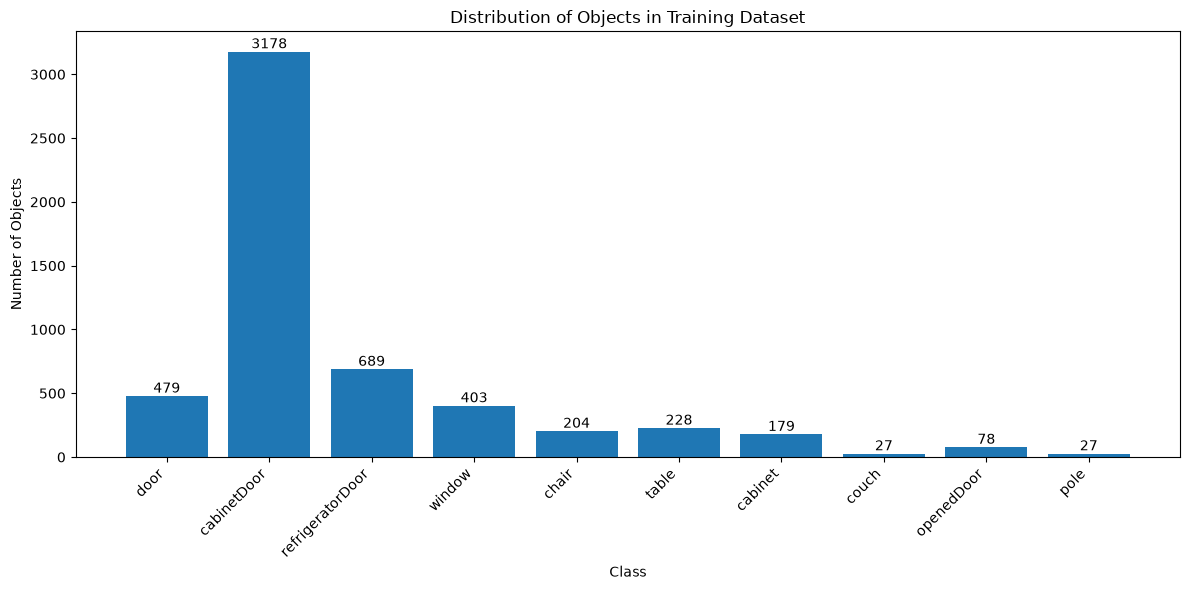

In [20]:
counts = [class_counts[i] for i in range(len(class_names))]

plt.figure(figsize=(12, 6))

bars = plt.bar(class_names, counts)

plt.title("Distribution of Objects in Training Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45, ha="right")

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [21]:
import random
from PIL import Image, ImageDraw

def show_yolo_image(image_path, label_path, class_names):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    width, height = image.size

    if label_path.exists():
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                class_id = int(parts[0])
                x_center, y_center, box_width, box_height = map(float, parts[1:])

                # YOLO normalized coordinates -> pixel coordinates
                x1 = (x_center - box_width / 2) * width
                y1 = (y_center - box_height / 2) * height
                x2 = (x_center + box_width / 2) * width
                y2 = (y_center + box_height / 2) * height

                draw.rectangle(
                    [x1, y1, x2, y2],
                    outline="red",
                    width=3
                )

                draw.text(
                    (x1, max(0, y1 - 15)),
                    class_names[class_id],
                    fill="red"
                )

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.axis("off")
    plt.title(image_path.name)
    plt.show()

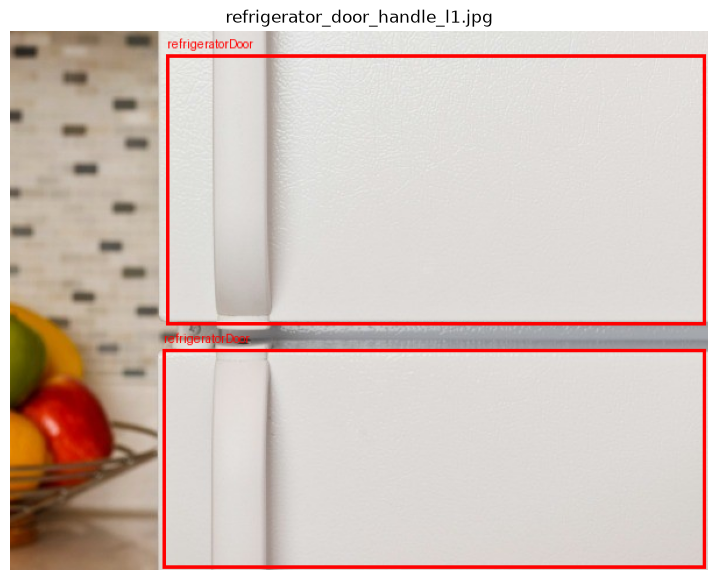

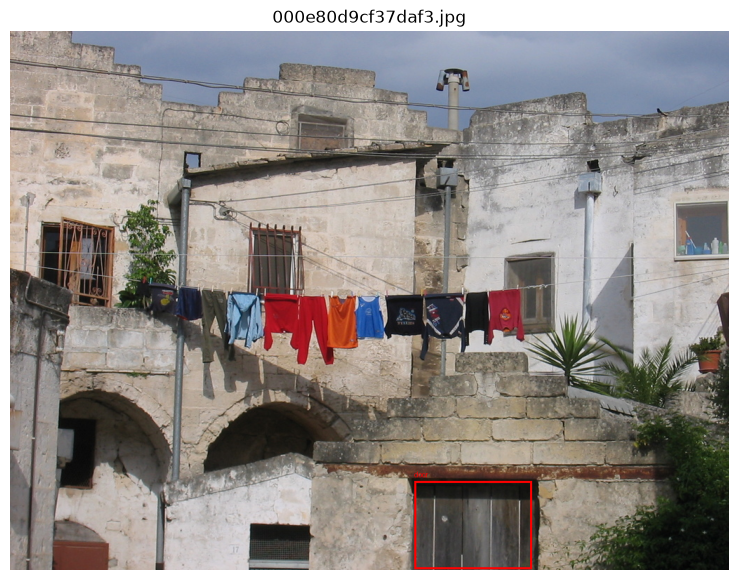

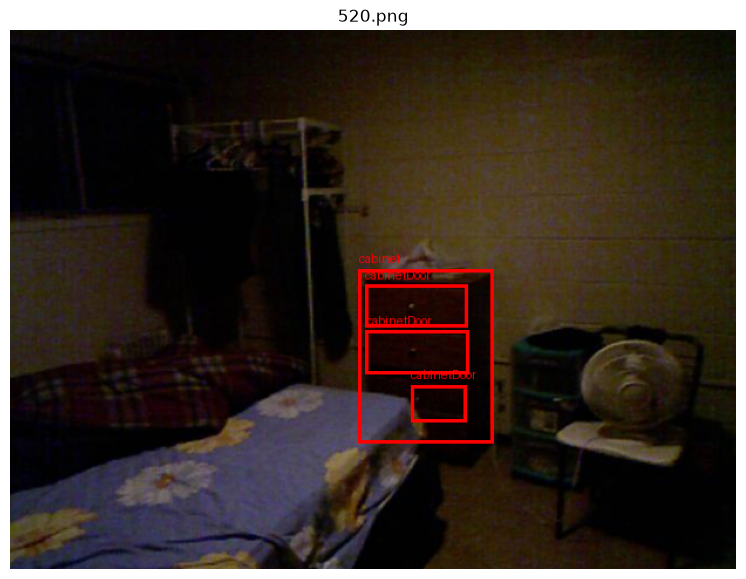

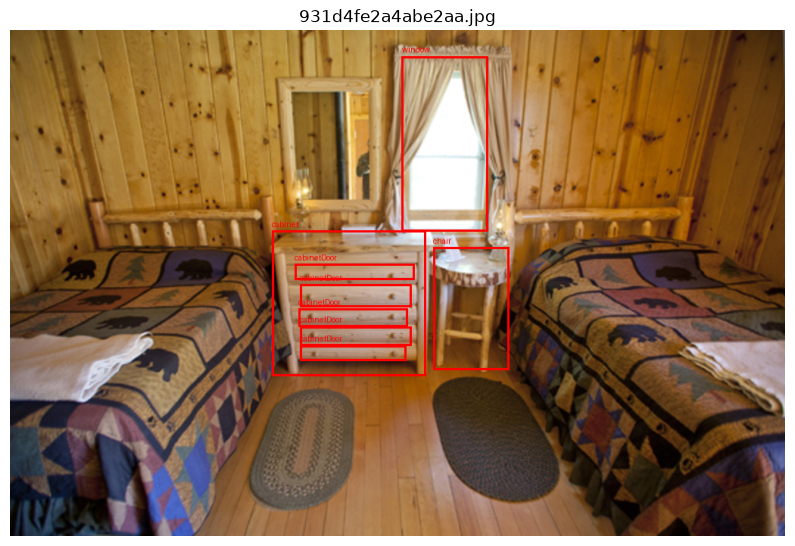

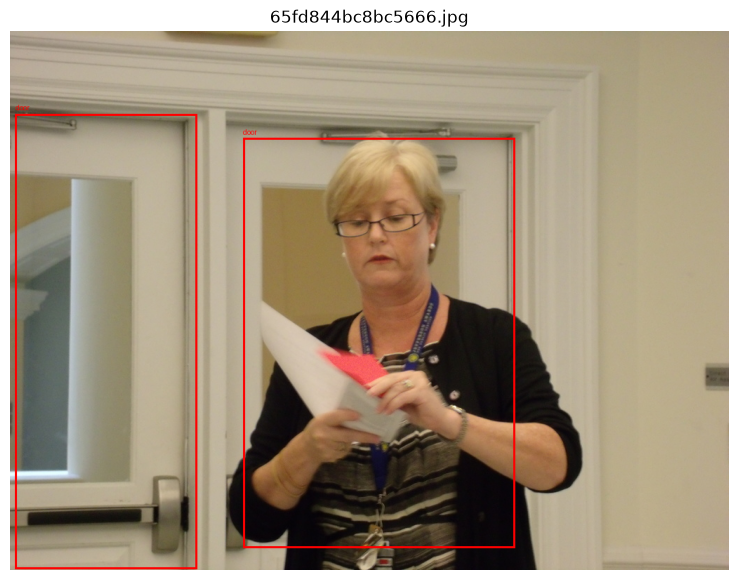

In [ ]:
train_images_dir = dataset_path / "train" / "images"
train_labels_dir = dataset_path / "train" / "labels"

image_files = [
    path for path in train_images_dir.iterdir()
    if path.suffix.lower() in IMAGE_EXTENSIONS
]

sample_images = random.sample(image_files, 5)

for image_path in sample_images:
    label_path = train_labels_dir / f"{image_path.stem}.txt"

    show_yolo_image(
        image_path,
        label_path,
        class_names
    )

In [23]:
def validate_labels(dataset_path, splits=("train", "valid", "test")):
    problems = []

    for split in splits:
        labels_dir = dataset_path / split / "labels"

        for label_file in labels_dir.glob("*.txt"):
            with open(label_file, "r") as f:
                for line_number, line in enumerate(f, start=1):
                    parts = line.strip().split()

                    if not parts:
                        continue

                    if len(parts) != 5:
                        problems.append(
                            (split, label_file.name, line_number, "Invalid format")
                        )
                        continue

                    try:
                        class_id = int(parts[0])
                        coords = list(map(float, parts[1:]))
                    except ValueError:
                        problems.append(
                            (split, label_file.name, line_number, "Invalid values")
                        )
                        continue

                    if not 0 <= class_id < len(class_names):
                        problems.append(
                            (split, label_file.name, line_number, "Invalid class ID")
                        )

                    if not all(0 <= value <= 1 for value in coords):
                        problems.append(
                            (split, label_file.name, line_number, "Coordinates outside [0, 1]")
                        )

    return problems


problems = validate_labels(dataset_path)

print("Problems found:", len(problems))

for problem in problems[:20]:
    print(problem)

Problems found: 0


In [24]:
# навчання моделі YOLO
from ultralytics import YOLO

model = YOLO("yolov9s.pt")

print(model)

results = model.train(
    data=str(local_yaml_path.resolve()),
    epochs=50,
    imgsz=640,
    batch=8,
    device="mps",
    workers=4,
    patience=10,
    project="runs/indoor_detection",
    name="yolov9s",
    pretrained=True,
    plots=True,
    verbose=True
)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): ELAN1(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps

/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

       1/50      6.58G      1.654      2.785      1.603         32        640: 100% ━━━━━━━━━━━━ 127/127 3.7it/s 34.8s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.2it/s 3.5s0.2s
                   all        230       1289      0.547      0.289      0.227      0.126

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      5.44G      1.479      1.914       1.49        105        640: 0% ──────────── 0/127  0.5s

/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

       2/50      6.48G      1.499       1.96      1.445         45        640: 100% ━━━━━━━━━━━━ 127/127 3.8it/s 33.5s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.9it/s 3.8s0.3s
                   all        230       1289      0.318      0.282      0.205      0.112

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


...

      34/50      6.46G      1.149     0.9089      1.248         50        640: 100% ━━━━━━━━━━━━ 127/127 3.9it/s 33.0s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.3it/s 3.5s0.2s
                   all        230       1289      0.581      0.475      0.469      0.314

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      35/50      6.45G      1.428      1.263      1.484         64        640: 0% ──────────── 0/127  0.5s

/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

      35/50      6.46G      1.136     0.9008      1.248         43        640: 100% ━━━━━━━━━━━━ 127/127 3.8it/s 33.3s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.3it/s 3.5s0.2s
                   all        230       1289      0.405      0.495      0.412      0.245

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      36/50      6.45G     0.9641     0.8515      1.136         49        640: 0% ──────────── 0/127  0.4s

/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/tetianareshetnik/Desktop/indoor-object-detection/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

      36/50      6.46G      1.143     0.8897      1.253         33        640: 100% ━━━━━━━━━━━━ 127/127 3.8it/s 33.0s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.4it/s 3.4s0.2s
                   all        230       1289      0.427      0.557      0.503      0.319
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 26, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

36 epochs completed in 0.400 hours.
Optimizer stripped from /Users/tetianareshetnik/Desktop/indoor-object-detection/runs/detect/runs/indoor_detection/yolov9s-2/weights/last.pt, 15.2MB
Optimizer stripped from /Users/tetianareshetnik/Desktop/indoor-object-detection/runs/detect/runs/indoor_detection/yolov9s-2/weights/best.pt, 15.2MB

Validating /Users/tetianareshetnik/Desktop/in

In [6]:
from pathlib import Path

best_path = Path(
    "/Users/tetianareshetnik/Desktop/indoor-object-detection/"
    "runs/detect/runs/indoor_detection/yolov9s-2/weights/best.pt"
)

print("Exists:", best_path.exists())
print("Path:", best_path)

Exists: True
Path: /Users/tetianareshetnik/Desktop/indoor-object-detection/runs/detect/runs/indoor_detection/yolov9s-2/weights/best.pt


In [8]:
from pathlib import Path

local_yaml_path = Path(
    "/Users/tetianareshetnik/Desktop/indoor-object-detection/indoor_data.yaml"
)

print("Exists:", local_yaml_path.exists())
print(local_yaml_path)

from ultralytics import YOLO

best_model = YOLO(str(best_path))

test_results = best_model.val(
    data=str(local_yaml_path.resolve()),
    split="test",
    imgsz=640,
    batch=8,
    device="mps",
    plots=True,
    verbose=True
)

Exists: True
/Users/tetianareshetnik/Desktop/indoor-object-detection/indoor_data.yaml
Ultralytics 8.4.172 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M5 Max)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1337.9±253.0 MB/s, size: 366.0 KB)
val: Scanning /Users/tetianareshetnik/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1/test/labels... 104 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 107/107 1.7Kit/s 0.1s
val: New cache created: /Users/tetianareshetnik/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 8.7it/s 1.6s<0.2s
                   all        107        550      0.437      0.434      0.386      0.192
                  door         25         34      0.625      0.441      0.405      0.208
           cabinetDoor    

In [9]:
class_names = [
    "door",
    "cabinetDoor",
    "refrigeratorDoor",
    "window",
    "chair",
    "table",
    "cabinet",
    "couch",
    "openedDoor",
    "pole"
]

import pandas as pd
import numpy as np

precision = test_results.box.p
recall = test_results.box.r

f1 = 2 * precision * recall / (precision + recall + 1e-8)

metrics_df = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "mAP50": test_results.box.ap50,
    "mAP50-95": test_results.box.ap
})

metrics_df.round(3)

,Class,Precision,Recall,F1-score,mAP50,mAP50-95
0,door,0.625,0.441,0.517,0.405,0.208
1,cabinetDoor,0.523,0.531,0.527,0.459,0.172
2,refrigeratorDoor,0.087,1.000,0.160,0.745,0.372
3,window,0.523,0.678,0.590,0.575,0.322
4,chair,0.355,0.402,0.377,0.378,0.206
5,table,0.272,0.277,0.274,0.270,0.128
6,cabinet,0.411,0.282,0.334,0.275,0.178
7,couch,0.284,0.259,0.271,0.165,0.066
8,openedDoor,0.308,0.223,0.259,0.175,0.104
9,pole,0.982,0.250,0.399,0.417,0.166


Results saved to:
/Users/tetianareshetnik/Desktop/indoor-object-detection/runs/detect/val
confusion_matrix.png
val_batch1_labels.jpg
BoxR_curve.png
val_batch2_pred.jpg
val_batch0_labels.jpg
confusion_matrix_normalized.png
BoxF1_curve.png
val_batch1_pred.jpg
val_batch0_pred.jpg
BoxP_curve.png
val_batch2_labels.jpg
BoxPR_curve.png


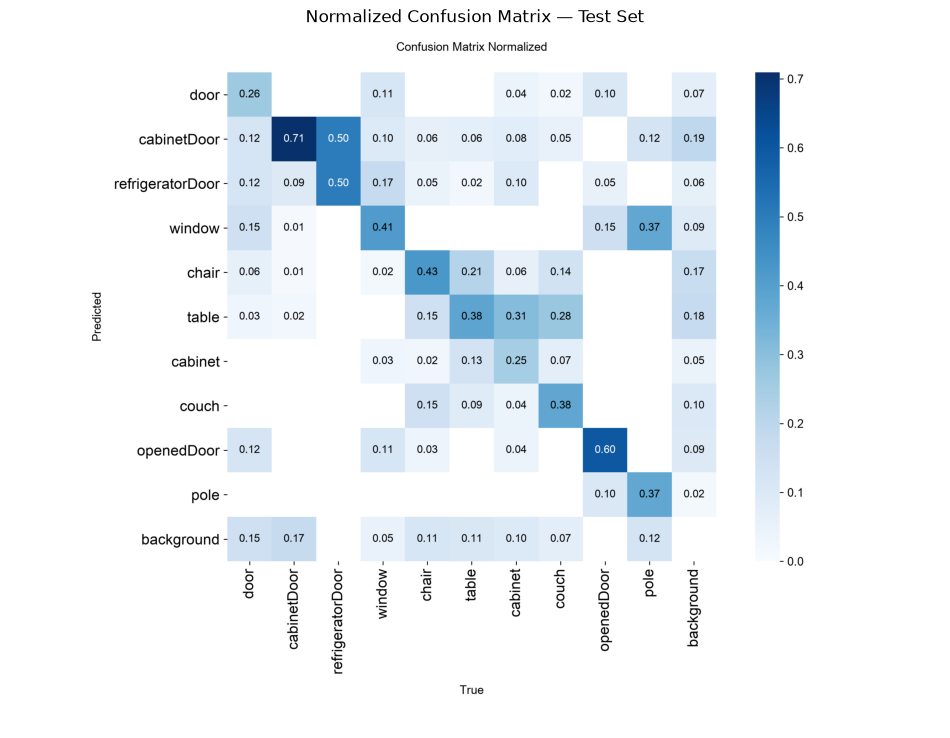

In [11]:
# Confusion Matrix

print("Results saved to:")
print(test_results.save_dir)

from pathlib import Path

results_dir = Path(test_results.save_dir)

for file in results_dir.iterdir():
    print(file.name)

from PIL import Image
import matplotlib.pyplot as plt

cm_path = results_dir / "confusion_matrix_normalized.png"

img = Image.open(cm_path)

plt.figure(figsize=(12, 10))
plt.imshow(img)
plt.axis("off")
plt.title("Normalized Confusion Matrix — Test Set")
plt.show()

### Аналіз матриці помилок

Нормалізована матриця помилок показує, що модель найстабільніше
розпізнає клас `cabinetDoor`. Значна частина об'єктів цього класу
класифікується правильно, що може бути пов'язано з великою кількістю
навчальних прикладів (3178 об'єктів у train-наборі).

Помітна плутанина спостерігається між візуально схожими класами.
Наприклад, `refrigeratorDoor` може класифікуватися як `cabinetDoor`,
оскільки обидва об'єкти мають схожу прямокутну форму та можуть мати
подібні візуальні характеристики. Водночас кількість
`refrigeratorDoor` у тестовому наборі дуже мала, тому оцінка цього
класу не є статистично надійною.

Також спостерігаються помилки між класами `chair`, `table`, `cabinet`
та `couch`. Ці предмети часто знаходяться поруч у приміщеннях,
можуть частково перекриватися та суттєво змінювати свій вигляд
залежно від кута зйомки.

Окремою проблемою є пропущені об'єкти, що відображаються через клас
`background`. Це свідчить про наявність false negative детекцій і
узгоджується з відносно невисоким загальним Recall моделі.

Однією з основних причин помилок є сильний дисбаланс навчального
набору. Наприклад, `cabinetDoor` представлений 3178 об'єктами,
тоді як `couch` і `pole` мають лише по 27 прикладів. Збільшення
кількості прикладів рідкісних класів та застосування додаткової
аугментації потенційно може покращити якість детекції.

Exists: True


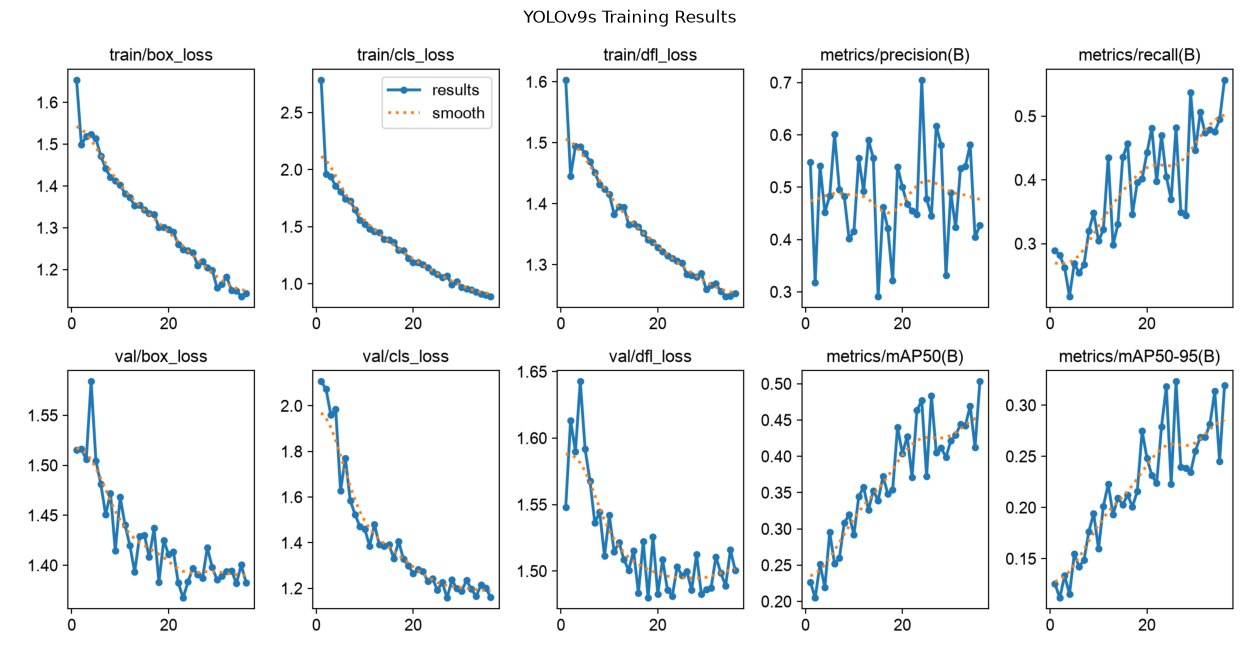

In [12]:
from PIL import Image
import matplotlib.pyplot as plt

training_results_path = Path(
    "/Users/tetianareshetnik/Desktop/indoor-object-detection/"
    "runs/detect/runs/indoor_detection/yolov9s-2/results.png"
)

print("Exists:", training_results_path.exists())

img = Image.open(training_results_path)

plt.figure(figsize=(16, 10))
plt.imshow(img)
plt.axis("off")
plt.title("YOLOv9s Training Results")
plt.show()

### Аналіз процесу навчання

Під час навчання YOLOv9s спостерігається стабільне зменшення
тренувальних функцій втрат `box_loss`, `cls_loss` та `dfl_loss`.
Це свідчить про те, що модель успішно навчається локалізувати та
класифікувати об'єкти.

Validation losses також загалом зменшуються. Приблизно після
20–25 епох їх покращення сповільнюється та спостерігаються
коливання навколо певного рівня. При цьому train losses продовжують
зменшуватися. Це може свідчити про вихід моделі на плато та початкові
ознаки перенавчання, однак значного розходження між training та
validation curves не спостерігається.

Метрики якості протягом навчання загалом покращуються. mAP@0.5
збільшується приблизно з 0.20 до 0.50, а mAP@0.5:0.95 — приблизно
з 0.12 до 0.32. Recall також демонструє загальну тенденцію до
зростання.

Precision має значні коливання між епохами. Однією з можливих причин
є відносно невеликий та сильно незбалансований набір даних:
кількість об'єктів різних класів суттєво відрізняється.

Загалом графіки не демонструють сильного перенавчання. Модель
навчилася корисних ознак, однак наприкінці навчання покращення
валідаційних показників сповільнюється.

In [14]:
from pathlib import Path
import random
import matplotlib.pyplot as plt

dataset_path = Path(
    "/Users/tetianareshetnik/.cache/kagglehub/"
    "datasets/thepbordin/indoor-object-detection/versions/1"
)

print("Dataset exists:", dataset_path.exists())

test_images_dir = dataset_path / "test" / "images"

test_images = [
    p for p in test_images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

print("Test images:", len(test_images))

sample_test_images = random.sample(test_images, 6)

predictions = best_model.predict(
    source=[str(p) for p in sample_test_images],
    imgsz=640,
    conf=0.25,
    device="mps",
    save=False
)

Dataset exists: True
Test images: 107

0: 480x640 4 couchs, 1.1ms
1: 480x640 1 door, 7 cabinetDoors, 1 window, 1 cabinet, 1.1ms
2: 480x640 (no detections), 1.1ms
3: 480x640 1 window, 1 table, 1.1ms
4: 480x640 1 refrigeratorDoor, 1 window, 1.1ms
5: 480x640 1 window, 1 cabinet, 1.1ms
Speed: 11.2ms preprocess, 1.1ms inference, 5.6ms postprocess per image at shape (1, 3, 480, 640)


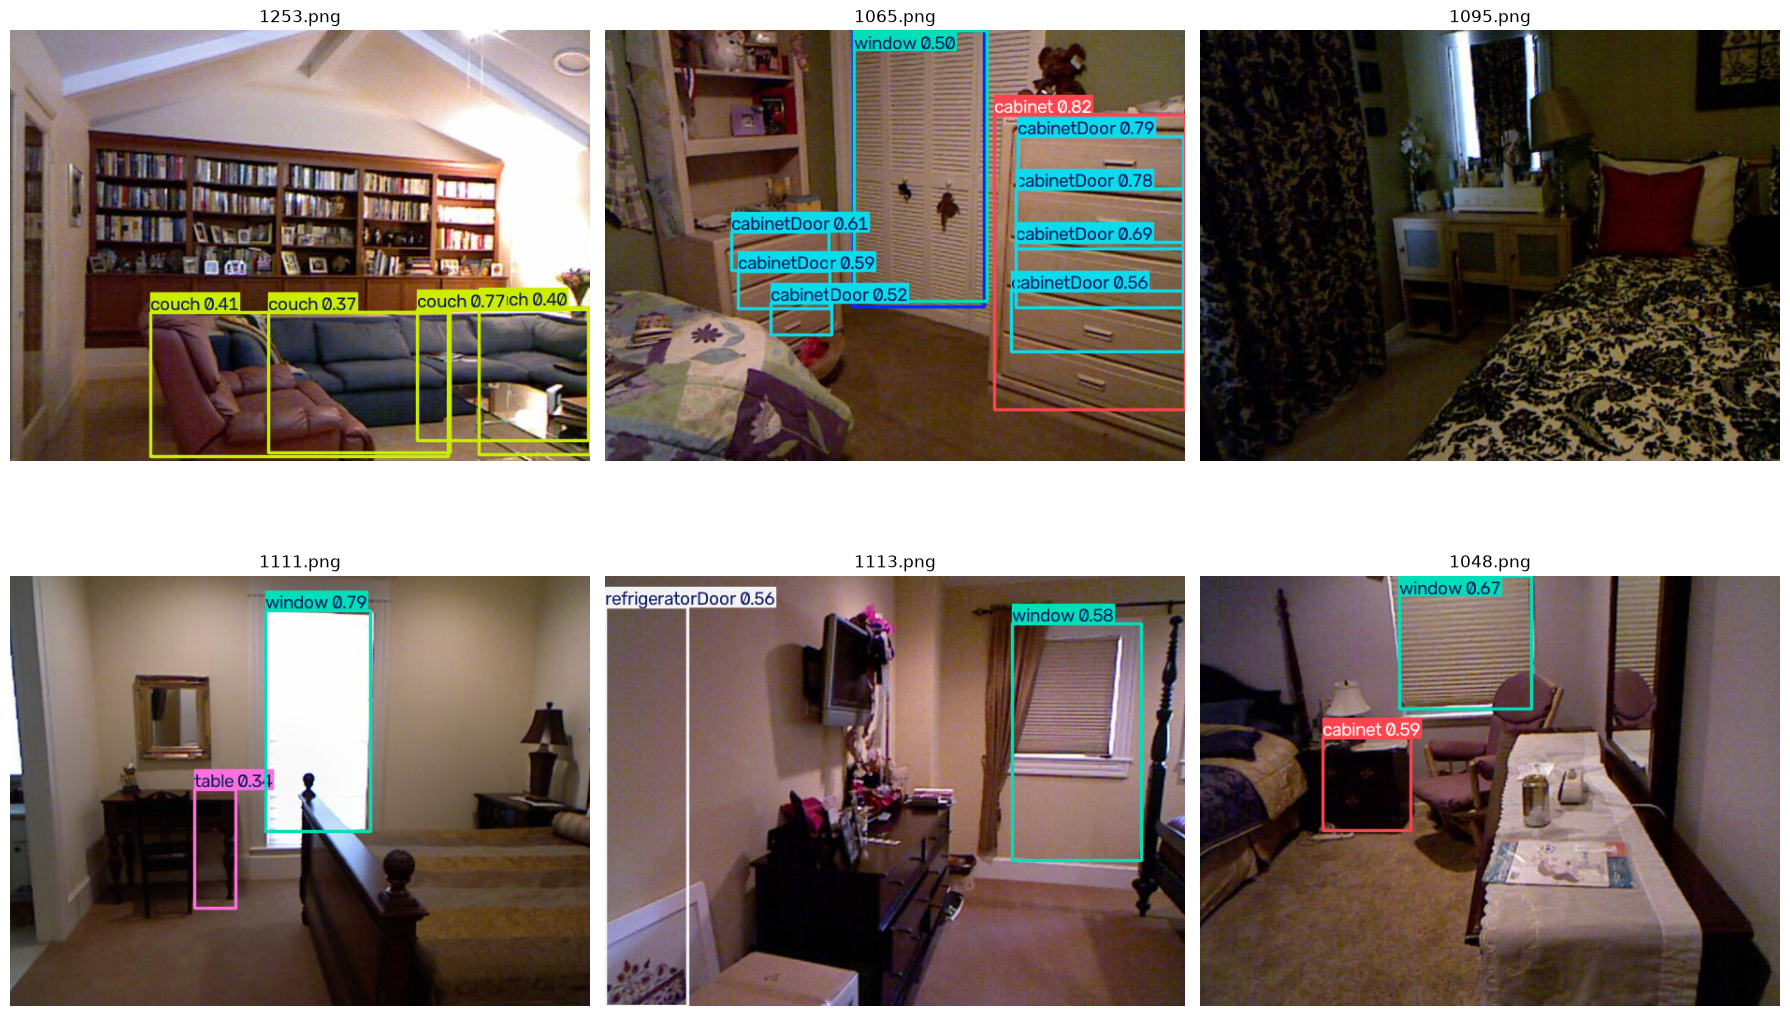

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, result in zip(axes.flat, predictions):
    plotted = result.plot()

    # BGR -> RGB
    plotted = plotted[:, :, ::-1]

    ax.imshow(plotted)
    ax.axis("off")
    ax.set_title(Path(result.path).name)

plt.tight_layout()
plt.show()

## Висновки

У межах роботи було розроблено модель детекції об'єктів у приміщенні
на основі архітектури YOLOv9s. Для навчання використано попередньо
натреновані ваги та механізм transfer learning.

Набір даних містить 10 класів об'єктів і має суттєвий дисбаланс.
Наприклад, у тренувальній вибірці клас `cabinetDoor` представлений
3178 об'єктами, тоді як `couch` і `pole` — лише 27 об'єктами кожен.
Це суттєво впливає на здатність моделі однаково добре навчитися
розпізнавати всі класи.

### Результати

На validation-наборі модель отримала приблизно:

- Precision: 0.445
- Recall: 0.482
- mAP@0.5: 0.484
- mAP@0.5:0.95: 0.323

На незалежному test-наборі з 107 зображень та 550 об'єктів:

- Precision: 0.437
- Recall: 0.434
- mAP@0.5: 0.386
- mAP@0.5:0.95: 0.192

Зниження метрик на test-наборі порівняно з validation-набором
свідчить про те, що узагальнення моделі на нових даних залишається
обмеженим.

Найкращий баланс Precision та Recall серед достатньо представлених
test-класів показав `window`:

- Precision = 0.523
- Recall = 0.678
- F1-score = 0.590
- mAP@0.5 = 0.575

Хороші результати також отримано для `door` та `cabinetDoor`:

- `door`: F1 = 0.517, mAP@0.5 = 0.405
- `cabinetDoor`: F1 = 0.527, mAP@0.5 = 0.459

Таким чином, модель демонструє прийнятну базову детекцію щонайменше
для трьох із десяти класів, а також частково розпізнає інші класи,
що відповідає основній меті завдання — створити робочий прототип,
здатний розпізнавати приблизно третину представлених типів об'єктів.

Високі окремі значення для `refrigeratorDoor` та `pole` необхідно
інтерпретувати обережно, оскільки у test-наборі представлено лише
2 та 8 об'єктів цих класів відповідно.

### Аналіз помилок

Confusion matrix показала, що модель плутає візуально схожі класи.
Зокрема, спостерігається плутанина між різними типами дверей і
дверцят, а також між `chair`, `table`, `cabinet` та `couch`.

На візуальних прикладах test-набору також виявлено:

- правильні детекції вікон і предметів меблів;
- false positive детекції;
- пропущені об'єкти (false negatives);
- випадки, коли один великий об'єкт отримує декілька bounding boxes;
- помилки класифікації візуально схожих об'єктів.

Learning curves показують стабільне зменшення training losses.
Validation losses також загалом зменшуються, але приблизно після
20–25 епох їх покращення сповільнюється та з'являються коливання.
Сильного перенавчання не спостерігається, однак модель поступово
виходить на плато.

### Можливі покращення

Основним напрямком покращення є балансування набору даних.
Необхідно додати більше прикладів рідкісних класів, зокрема
`couch`, `pole` та `openedDoor`.

Також доцільно:

1. Застосувати додаткову аугментацію для рідкісних класів.
2. Перевірити та за необхідності покращити якість bounding-box
   анотацій.
3. Збільшити обсяг тренувального набору та різноманітність сцен.
4. Провести tuning параметрів навчання: learning rate, batch size,
   image size та параметрів аугментації.
5. Спробувати більшу модель YOLO та порівняти її з YOLOv9s.
6. Провести окремий аналіз confidence threshold та IoU/NMS
   параметрів для зменшення false positives і дубльованих детекцій.
7. Збільшити кількість прикладів валідаційної та тестової вибірок
   для рідкісних класів, щоб отримати більш надійні метрики.

### Загальний висновок

YOLOv9s успішно навчилася знаходити та класифікувати частину
об'єктів у приміщенні. Найкращі результати отримано для вікон,
дверей та дверцят шаф.

Хоча загальний test mAP@0.5 = 0.386 є дещо нижчим за орієнтовний
діапазон 0.40–0.60, модель демонструє працездатний прототип системи
object detection. Основним фактором, що обмежує якість, є сильний
дисбаланс класів та мала кількість прикладів окремих категорій.

Отримані результати показують, що подальше балансування даних,
розширення датасету та оптимізація параметрів навчання можуть
суттєво покращити здатність моделі до узагальнення.